In [1]:
import sys
import pandas as pd
import numpy as np

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Environment ready!")

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]
Pandas version: 2.2.3
NumPy version: 2.1.3
Environment ready!


In [2]:
import pandas as pd
from pathlib import Path

data_files = {
    "demographics": "customer_demographics_contaminated.csv",
    "transactions": "customer_transactions_contaminated.csv",
    "social_media": "social_media_interactions_contaminated.csv"
}

datasets = {}

for name, filename in data_files.items():
    path = Path(filename)

    if not path.exists():
        print(f"FILE NOT FOUND: {filename}")
        continue

    df = pd.read_csv(path)
    datasets[name] = df

    print(f"\n{'=' * 55}")
    print(f"DATASET: {name.upper()}")
    print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
    print("\nColumn types:")
    print(df.dtypes)
    print("\nMissing values per column:")
    print(df.isna().sum())
    print("\nExact duplicate rows:", df.duplicated().sum())
    print("\nFirst five rows:")
    display(df.head())


DATASET: DEMOGRAPHICS
Rows: 3200 | Columns: 6

Column types:
CustomerID     object
Age            object
Gender         object
Location       object
IncomeLevel    object
SignupDate     object
dtype: object

Missing values per column:
CustomerID       0
Age            291
Gender           0
Location         0
IncomeLevel    303
SignupDate       0
dtype: int64

Exact duplicate rows: 177

First five rows:


,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
0,9207fa75-5758-48d1-94ad-19c041e0520f,51.0,Female,Jensenberg,Low,2022-11-17
1,5fb09cd8-a473-46f7-80bd-6e49cf509078,NaN,Female,Castilloport,High,2020-07-21
2,c139496e-cc89-498a-bd90-1fb4627b6cff,37.0,Male,Lake Jennifertown,NaN,2021-01-01
3,50118139-7264-428f-81cc-a25fddc5d6dd,44.0,Male,Port Carl,Medium,2024-06-10
4,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50.0,Female,Jessebury,High,2023-08-24



DATASET: TRANSACTIONS
Rows: 3200 | Columns: 6

Column types:
CustomerID         object
TransactionID      object
TransactionDate    object
Amount             object
ProductCategory    object
PaymentMethod      object
dtype: object

Missing values per column:
CustomerID           0
TransactionID        0
TransactionDate      0
Amount             304
ProductCategory    299
PaymentMethod        0
dtype: int64

Exact duplicate rows: 185

First five rows:


,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod
0,60567026-f719-4cd6-849e-137e86d8938f,5ff75116-0a50-4d04-80fb-31e5ccbb0769,2024-05-15,117.64,Clothing,PayPal
1,4090ba85-b111-4f75-a792-c777965f5255,2c39b9fe-ff57-4d39-9321-9f5cdf187aa1,2023-04-26,466.14,Health & Beauty,Bank Transfer
2,9223891b-73ff-4d5c-b8ae-13ece82ee28b,f79588dd-3db9-4ffa-97f8-7de0e64259f1,2022-09-23,563.99,Clothing,Debit Card
3,9243eebc-938f-480c-8564-16d503d250de,401c0fc9-60df-4455-ad78-67c132f9897d,2024-04-15,254.44,Automotive,PayPal
4,6e3e8eb8-bc0f-4ffe-9f74-5d5efec9502f,2034aebc-8280-4254-a667-92bcd1c2be4f,2024-06-03,590.52,Home & Garden,Bank Transfer



DATASET: SOCIAL_MEDIA
Rows: 3200 | Columns: 6

Column types:
CustomerID         object
InteractionID      object
InteractionDate    object
Platform           object
InteractionType    object
Sentiment          object
dtype: object

Missing values per column:
CustomerID           0
InteractionID        0
InteractionDate      0
Platform           311
InteractionType      0
Sentiment          329
dtype: int64

Exact duplicate rows: 180

First five rows:


,CustomerID,InteractionID,InteractionDate,Platform,InteractionType,Sentiment
0,2dcb9523-356b-40b2-a67b-1f27797de261,e5d15761-d0a7-4329-89e3-79a892c56097,2023-07-11,NaN,Comment,NaN
1,e12c37b3-7d4d-472f-9fd8-0df2cb3001aa,02f9f376-70ae-4fcd-9070-1db977939948,2023-07-06,Twitter,Share,NaN
2,08a911a3-65e6-4f5d-a6a1-ae7ddcbe28a2,a83fa04c-f109-4f24-8ce1-2078154f6a1c,2024-05-24,Instagram,Comment,Neutral
3,efdfdfc9-5dbb-4478-911a-101a390a0285,28a69c4b-a2e4-4c74-a130-1132d7733fdf,2023-11-01,Instagram,Like,Neutral
4,ca1e90f6-0e5f-492e-ab92-252ff540da18,d9d1c6f8-5e15-4738-b52b-13c2982420cc,2023-07-08,Instagram,Like,NaN


In [3]:

# Inspect suspicious values before making changes

columns_to_check = {
    "demographics": ["Age", "IncomeLevel", "SignupDate"],
    "transactions": [
        "Amount", "ProductCategory", "TransactionDate"
    ],
    "social_media": [
        "Platform", "Sentiment", "InteractionDate"
    ]
}

for name, columns in columns_to_check.items():
    df = datasets[name]

    print(f"\n{'=' * 60}")
    print(name.upper())

    for col in columns:
        print(f"\n--- {col} ---")
        print("Distinct non-null values:", df[col].nunique())
        print("Most frequent values:")
        display(df[col].value_counts(dropna=False).head(15))

# Check identifier uniqueness
for name, df in datasets.items():
    id_columns = [
        col for col in df.columns
        if col.endswith("ID")
    ]

    print(f"\n{name.upper()} identifier checks:")
    for col in id_columns:
        print(
            f"{col}:",
            f"{df[col].nunique()} unique values out of {len(df)} rows"
        )



DEMOGRAPHICS

--- Age ---
Distinct non-null values: 58
Most frequent values:


Age
NaN     291
26.0     72
57.0     72
62.0     71
34.0     70
68.0     66
43.0     60
55.0     60
18.0     59
52.0     59
53.0     58
27.0     58
70.0     58
45.0     58
61.0     57
Name: count, dtype: int64


--- IncomeLevel ---
Distinct non-null values: 3
Most frequent values:


IncomeLevel
High      1004
Low        985
Medium     908
NaN        303
Name: count, dtype: int64


--- SignupDate ---
Distinct non-null values: 1544
Most frequent values:


...


--- Sentiment ---
Distinct non-null values: 5
Most frequent values:


Sentiment
Positive         962
Negative         925
Neutral          918
NaN              329
Very Negative     34
Very Positive     32
Name: count, dtype: int64


--- InteractionDate ---
Distinct non-null values: 450
Most frequent values:


InteractionDate
2023-07-02    17
2023-12-02    17
2024-06-29    16
2023-12-27    16
2023-09-15    16
2024-01-30    16
2024-01-13    15
2023-12-18    15
2024-02-26    15
2023-11-30    14
2023-07-26    14
2024-01-11    14
2024-02-12    14
2023-07-11    14
2024-02-16    14
Name: count, dtype: int64


DEMOGRAPHICS identifier checks:
CustomerID: 3000 unique values out of 3200 rows

TRANSACTIONS identifier checks:
CustomerID: 1871 unique values out of 3200 rows
TransactionID: 3000 unique values out of 3200 rows

SOCIAL_MEDIA identifier checks:
CustomerID: 1893 unique values out of 3200 rows
InteractionID: 3000 unique values out of 3200 rows


In [4]:

# Week 2: Detailed data-quality checks
import pandas as pd

# 1. Demographic age checks
demo = datasets["demographics"].copy()
age_num = pd.to_numeric(demo["Age"], errors="coerce")

print("DEMOGRAPHICS")
print("Non-missing ages that cannot be converted:",
      (demo["Age"].notna() & age_num.isna()).sum())
print("Ages below 18:", (age_num < 18).sum())
print("Ages above 100:", (age_num > 100).sum())
print("Invalid age examples:")
display(demo.loc[
    age_num.isna() | (age_num < 18) | (age_num > 100),
    ["CustomerID", "Age"]
].head(20))

# 2. Transaction amount checks
trans = datasets["transactions"].copy()
amount_num = pd.to_numeric(trans["Amount"], errors="coerce")

print("\nTRANSACTIONS")
print("Non-missing amounts that cannot be converted:",
      (trans["Amount"].notna() & amount_num.isna()).sum())
print("Negative numeric amounts:", (amount_num < 0).sum())
print("Zero numeric amounts:", (amount_num == 0).sum())
print("Amount examples that cannot be converted:")
display(trans.loc[
    trans["Amount"].notna() & amount_num.isna(),
    ["TransactionID", "Amount"]
].head(20))
print("Negative amount examples:")
display(trans.loc[
    amount_num < 0,
    ["TransactionID", "Amount", "ProductCategory"]
].head(20))

# 3. Date validation
date_columns = {
    "demographics": "SignupDate",
    "transactions": "TransactionDate",
    "social_media": "InteractionDate"
}

print("\nDATE VALIDATION")
for name, col in date_columns.items():
    df = datasets[name]
    parsed = pd.to_datetime(df[col], errors="coerce")
    invalid = df[col].notna() & parsed.isna()
    print(f"{name}: {invalid.sum()} non-missing dates that cannot be parsed")
    if invalid.any():
        display(df.loc[invalid, [col]].head(10))

# 4. Check repeated IDs for conflicting records
for name, id_col in [
    ("demographics", "CustomerID"),
    ("transactions", "TransactionID"),
    ("social_media", "InteractionID")
]:
    df = datasets[name]
    repeated = df[df.duplicated(id_col, keep=False)].sort_values(id_col)

    print(f"\n{name.upper()} — repeated {id_col} records")
    print("Rows with a repeated ID:", len(repeated))
    print("Distinct repeated IDs:", repeated[id_col].nunique())

    if not repeated.empty:
        display(repeated.head(12))


DEMOGRAPHICS
Non-missing ages that cannot be converted: 34
Ages below 18: 30
Ages above 100: 33
Invalid age examples:


,CustomerID,Age
1,5fb09cd8-a473-46f7-80bd-6e49cf509078,NaN
6,89f7de44-e592-43c6-b033-bcbcf24088ba,NaN
7,9f2128cd-2f2b-4f71-987c-29fd045021f0,NaN
8,fbcd7128-ce04-4799-8c1c-722330507b96,NaN
9,40f5a5dd-a46f-4a5e-8c0f-fe04389ddec8,NaN
10,c96a5ee9-f1a6-416a-adc6-1c8b128c7399,150
11,7f87735e-2345-4e9f-84e9-149fc0f168f7,NaN
12,aae60ad7-5553-4d10-a637-93d5dcc98e4a,NaN
14,dc7f151c-dd0b-44b7-9ea2-ab684e50d463,NaN
23,fd63f236-3ec3-401d-9fa1-53bda0bd7c0e,NaN



TRANSACTIONS
Non-missing amounts that cannot be converted: 30
Negative numeric amounts: 40
Zero numeric amounts: 30
Amount examples that cannot be converted:


,TransactionID,Amount
5,78dfb45e-16e0-4ecc-8f67-f2e210c31c3e,Free
59,611876da-a85d-4969-8d84-7a9cf8ddbf59,Free
161,b7e042d1-7ad0-430d-8984-82dfa9048a64,Free
250,cd29e076-8de9-416b-bc0e-fecb61c8baff,Free
432,36d14454-fb95-4b19-a574-e137ddb55528,Free
755,a7e2384a-9efb-4519-aa01-683daa01d6e9,Free
764,983162b4-b06e-41d3-956c-2c3eed3cf6c4,Free
786,f9cdb10b-2e40-4df2-a7c4-3614151587b6,Free
853,519f279a-5e5d-4a98-8a28-6c04e66c62b7,Free
854,87459f1a-8873-450f-8b7d-ac4c7b41ba90,Free


Negative amount examples:


...

,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
3039,0047d8ce-a5bb-4db7-860f-6ff66e1cd060,40.0,Male,Mitchellview,Medium,2021-11-11
2559,0047d8ce-a5bb-4db7-860f-6ff66e1cd060,40.0,Male,Mitchellview,Medium,2021-11-11
1511,05609335-a647-4691-80a8-82b43518b767,52.0,Male,Jonesside,Low,2023-10-07
3169,05609335-a647-4691-80a8-82b43518b767,52.0,Male,Jonesside,Low,2023-10-07
3061,06af0246-5f53-45f4-997e-bf42706b11d7,53.0,Male,Stevenberg,NaN,2022-11-25
1105,06af0246-5f53-45f4-997e-bf42706b11d7,53.0,Male,Stevenberg,NaN,2022-11-25
2409,077936e6-6556-434f-9494-e5d671b6e71c,65.0,Female,Bryantside,High,2019-11-09
3199,077936e6-6556-434f-9494-e5d671b6e71c,65.0,Female,Bryantside,High,2019-11-09
3024,08995799-8d0f-40d6-986b-452074709b5f,61.0,Male,New Lukeville,Medium,2020-03-28
1536,08995799-8d0f-40d6-986b-452074709b5f,61.0,Male,New Lukeville,Medium,15/11/2019



TRANSACTIONS — repeated TransactionID records
Rows with a repeated ID: 400
Distinct repeated IDs: 200


,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod
3010,42d3c5b0-ec77-4567-b66c-449783077049,02221793-d5ba-4064-99d8-33c1b6722278,2023-10-03,911.51,Electronics,Credit Card
1347,42d3c5b0-ec77-4567-b66c-449783077049,02221793-d5ba-4064-99d8-33c1b6722278,2023-10-03,911.51,Electronics,Credit Card
3005,778da54b-8f96-4609-a21b-bba3d7f071ea,022cfd97-a8e8-4e50-8700-2720d52bfd75,2022-08-23,Free,Health & Beauty,PayPal
2118,778da54b-8f96-4609-a21b-bba3d7f071ea,022cfd97-a8e8-4e50-8700-2720d52bfd75,2022-08-23,586.87,Health & Beauty,PayPal
3131,9ecddfde-5bba-42c0-b4a4-8eb1b8f87c17,02747865-0adb-4e26-be16-078b8e38dcde,2022-08-30,627.83,NaN,Credit Card
2360,9ecddfde-5bba-42c0-b4a4-8eb1b8f87c17,02747865-0adb-4e26-be16-078b8e38dcde,2022-08-30,627.83,NaN,Credit Card
282,b10dbfea-ac81-4cdf-be3c-62248bbd5838,02a36fd6-8d10-4179-8b84-f011e8551a64,2024-06-02,NaN,Health & Beauty,Debit Card
3127,b10dbfea-ac81-4cdf-be3c-62248bbd5838,02a36fd6-8d10-4179-8b84-f011e8551a64,2024-06-02,NaN,Health & Beauty,Debit Card
3015,4090ba85-b111-4f75-a792-c777965f5255,04edc4fc-1565-4a82-af75-5b5caacaa9c4,2024-06-27,138.72,Home & Garden,Bank Transfer
767,4090ba85-b111-4f75-a792-c777965f5255,04edc4fc-1565-4a82-af75-5b5caacaa9c4,2024-06-27,138.72,Home & Garden,Bank Transfer



SOCIAL_MEDIA — repeated InteractionID records
Rows with a repeated ID: 400
Distinct repeated IDs: 200


,CustomerID,InteractionID,InteractionDate,Platform,InteractionType,Sentiment
2511,5db2e5ed-d30c-45db-b5f1-9db8008e178b,012dbb2a-3fbe-4b98-aa69-0304704db3c2,2024-05-26,NaN,Comment,Neutral
3176,5db2e5ed-d30c-45db-b5f1-9db8008e178b,012dbb2a-3fbe-4b98-aa69-0304704db3c2,2024-05-26,NaN,Comment,Neutral
1820,2ad7dcee-ed9c-4a7f-b631-377268bc623b,019fe9c3-83c6-49e4-b827-5ddd614c72df,2024-03-14,Instagram,Comment,Positive
3088,2ad7dcee-ed9c-4a7f-b631-377268bc623b,019fe9c3-83c6-49e4-b827-5ddd614c72df,2024-03-14,Instagram,Comment,Positive
3005,11b046f0-b091-4bfb-b0f4-df58bfea039a,01f1c8c8-df21-4d75-adbb-feb6d4c84317,2024-03-20,Instagram,Like,Positive
374,11b046f0-b091-4bfb-b0f4-df58bfea039a,01f1c8c8-df21-4d75-adbb-feb6d4c84317,29/04/2024,Instagram,Like,Positive
3118,0c298fc3-6e30-4478-bc30-f1b56b2e655d,020837db-5783-4ac9-9955-1ace5175a1a0,2023-07-05,Facebook,Share,Positive
1051,0c298fc3-6e30-4478-bc30-f1b56b2e655d,020837db-5783-4ac9-9955-1ace5175a1a0,2023-07-05,Facebook,Share,Positive
2604,4a75d71b-1263-43c3-9533-a0b94f50fee0,02fe2369-cc53-4053-b8c3-5c29f98087dc,2023-09-19,Twitter,Comment,Neutral
3079,4a75d71b-1263-43c3-9533-a0b94f50fee0,02fe2369-cc53-4053-b8c3-5c29f98087dc,2023-09-19,Twitter,Comment,Neutral


In [5]:

# Week 2: Initial preprocessing pass
# Original files remain unchanged.

import pandas as pd
from pathlib import Path

# Copy the datasets already loaded into memory
cleaned = {
    name: df.copy()
    for name, df in datasets.items()
}

# Remove exact duplicate rows only
for name, df in cleaned.items():
    before = len(df)
    df.drop_duplicates(inplace=True)
    print(
        f"{name}: removed {before - len(df)} exact duplicate rows; "
        f"{len(df)} rows remain."
    )

# Standardize demographic data types
demo = cleaned["demographics"]
demo["Age"] = pd.to_numeric(demo["Age"], errors="coerce")

# Treat implausible ages as missing pending verification.
invalid_age = (demo["Age"] < 18) | (demo["Age"] > 100)
demo.loc[invalid_age, "Age"] = pd.NA

# Standardize transaction amounts
trans = cleaned["transactions"]
trans["Amount"] = pd.to_numeric(trans["Amount"], errors="coerce")

# Standardize dates using mixed-format parsing.
# Requires a recent Pandas version.
date_columns = {
    "demographics": "SignupDate",
    "transactions": "TransactionDate",
    "social_media": "InteractionDate"
}

for name, col in date_columns.items():
    df = cleaned[name]
    df[col] = pd.to_datetime(
        df[col],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

# Review the first-pass results; nothing has been exported yet.
for name, df in cleaned.items():
    print(f"\n--- {name.upper()} ---")
    print("Rows:", len(df))
    print("Remaining exact duplicates:", df.duplicated().sum())
    print("\nMissing values:")
    print(df.isna().sum())
    print("\nData types:")
    print(df.dtypes)


demographics: removed 177 exact duplicate rows; 3023 rows remain.
transactions: removed 185 exact duplicate rows; 3015 rows remain.
social_media: removed 180 exact duplicate rows; 3020 rows remain.

--- DEMOGRAPHICS ---
Rows: 3023
Remaining exact duplicates: 0

Missing values:
CustomerID       0
Age            373
Gender           0
Location         0
IncomeLevel    285
SignupDate       0
dtype: int64

Data types:
CustomerID             object
Age                   float64
Gender                 object
Location               object
IncomeLevel            object
SignupDate     datetime64[ns]
dtype: object

--- TRANSACTIONS ---
Rows: 3015
Remaining exact duplicates: 0

Missing values:
CustomerID           0
TransactionID        0
TransactionDate      0
Amount             313
ProductCategory    282
PaymentMethod        0
dtype: int64

Data types:
CustomerID                 object
TransactionID              object
TransactionDate    datetime64[ns]
Amount                    float64
ProductC

In [6]:

# Validate date conversions and identifier uniqueness

date_columns = {
    "demographics": ("SignupDate", "CustomerID"),
    "transactions": ("TransactionDate", "TransactionID"),
    "social_media": ("InteractionDate", "InteractionID")
}

for name, (date_col, id_col) in date_columns.items():
    df = cleaned[name]

    print(f"\n{'=' * 50}")
    print(name.upper())

    # Date checks
    print("Missing dates:", df[date_col].isna().sum())
    print("Earliest date:", df[date_col].min())
    print("Latest date:", df[date_col].max())

    # Identifier checks
    print("Unique IDs:", df[id_col].nunique())
    print("Rows with repeated IDs:",
          df.duplicated(subset=[id_col], keep=False).sum())

    repeated = df[df.duplicated(subset=[id_col], keep=False)]
    if not repeated.empty:
        print("Sample repeated-ID records:")
        display(repeated.sort_values(id_col).head(10))

# Check remaining suspicious numerical values
print("\nDEMOGRAPHIC AGE SUMMARY")
display(cleaned["demographics"]["Age"].describe())

print("\nTRANSACTION AMOUNT SUMMARY")
display(cleaned["transactions"]["Amount"].describe())

print("\nNegative transaction amounts:")
display(
    cleaned["transactions"].loc[
        cleaned["transactions"]["Amount"] < 0,
        ["TransactionID", "Amount", "ProductCategory"]
    ].head(20)
)



DEMOGRAPHICS
Missing dates: 0
Earliest date: 2019-07-01 00:00:00
Latest date: 2024-06-30 00:00:00
Unique IDs: 3000
Rows with repeated IDs: 46
Sample repeated-ID records:


,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
3024,08995799-8d0f-40d6-986b-452074709b5f,61.0,Male,New Lukeville,Medium,2020-03-28
1536,08995799-8d0f-40d6-986b-452074709b5f,61.0,Male,New Lukeville,Medium,2019-11-15
3085,1e9e7dcb-e612-46d3-bae6-0c2f47fa0220,44.0,Female,Brianmouth,Medium,2019-11-07
304,1e9e7dcb-e612-46d3-bae6-0c2f47fa0220,44.0,Female,Brianmouth,Medium,2022-07-28
3083,29436bcf-d6f8-44d1-a856-0794abb562ab,68.0,Female,New Fred,Low,2020-03-12
754,29436bcf-d6f8-44d1-a856-0794abb562ab,68.0,Female,New Fred,Low,2021-09-01
3051,2cd16dfc-d7b0-47ec-9999-b018daea7f8d,52.0,Female,Lake Carloshaven,Medium,2024-05-02
2106,2cd16dfc-d7b0-47ec-9999-b018daea7f8d,NaN,Female,Lake Carloshaven,Medium,2024-05-02
1238,3814b8e4-cade-4665-86af-dda3e3628f17,32.0,Female,Port Bonnieshire,Medium,2021-06-25
3004,3814b8e4-cade-4665-86af-dda3e3628f17,NaN,Female,Port Bonnieshire,Medium,2021-06-25



TRANSACTIONS
Missing dates: 0
Earliest date: 2022-07-01 00:00:00
Latest date: 2024-06-30 00:00:00
Unique IDs: 3000
Rows with repeated IDs: 30
Sample repeated-ID records:


,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod
2118,778da54b-8f96-4609-a21b-bba3d7f071ea,022cfd97-a8e8-4e50-8700-2720d52bfd75,2022-08-23,586.87,Health & Beauty,PayPal
3005,778da54b-8f96-4609-a21b-bba3d7f071ea,022cfd97-a8e8-4e50-8700-2720d52bfd75,2022-08-23,NaN,Health & Beauty,PayPal
3174,6a84f1a7-f636-4300-bd8d-c7f888460829,185ee140-348a-4461-bd40-07a7e8535815,2023-10-09,0.00,Health & Beauty,PayPal
413,6a84f1a7-f636-4300-bd8d-c7f888460829,185ee140-348a-4461-bd40-07a7e8535815,2023-10-09,953.86,Health & Beauty,PayPal
3038,b94b3531-591d-445c-b282-dcacb0baca5b,27fb25aa-f148-423f-967c-4d1764e26b29,2024-04-18,-100.00,Automotive,Credit Card
431,b94b3531-591d-445c-b282-dcacb0baca5b,27fb25aa-f148-423f-967c-4d1764e26b29,2022-07-30,506.96,Automotive,Credit Card
2081,e7cf6999-b4ec-4ce4-bb09-bfd18d61d933,2e0b66a9-af5d-4cf9-bb60-55ab2932edee,2023-05-10,504.42,Electronics,Bank Transfer
3073,e7cf6999-b4ec-4ce4-bb09-bfd18d61d933,2e0b66a9-af5d-4cf9-bb60-55ab2932edee,2023-05-10,-100.00,Electronics,Bank Transfer
3050,a9af986b-d677-421a-81df-3d289ce9e38f,5f93f1dc-0363-4e69-979b-f5d58fd42658,2023-09-30,-100.00,NaN,Bank Transfer
220,a9af986b-d677-421a-81df-3d289ce9e38f,5f93f1dc-0363-4e69-979b-f5d58fd42658,2023-09-30,125.77,NaN,Bank Transfer



SOCIAL_MEDIA
Missing dates: 0
Earliest date: 2023-07-01 00:00:00
Latest date: 2024-06-30 00:00:00
Unique IDs: 3000
Rows with repeated IDs: 40
Sample repeated-ID records:


...

count    2650.000000
mean       44.644906
std        15.405637
min        18.000000
25%        31.000000
50%        45.000000
75%        58.000000
max        70.000000
Name: Age, dtype: float64


TRANSACTION AMOUNT SUMMARY


count    2702.000000
mean      489.788919
std       299.239453
min      -100.000000
25%       228.240000
50%       496.625000
75%       746.697500
max       999.860000
Name: Amount, dtype: float64


Negative transaction amounts:


,TransactionID,Amount,ProductCategory
274,814d25d8-690b-45bb-96c9-b7a3e92a61db,-100.0,NaN
319,fb908e24-4c1e-4e24-a1b0-62465fa0515c,-100.0,Health & Beauty
334,487ecd9b-57c8-447c-a2a8-e55477ba0d6d,-100.0,Clothing
381,f53b16b4-d042-44ca-a073-4acdd546b519,-100.0,Home & Garden
447,f35cadbe-6ae1-427d-8b41-5749cc1173e6,-100.0,Electronics
449,77954a26-9a04-4806-b525-7f33f554d255,-100.0,Home & Garden
476,1074d2cf-a7d5-4ebd-baa9-4660b2df5ec8,-100.0,Health & Beauty
500,c59819cc-cf92-4929-ad22-ef3435187be9,-100.0,Automotive
563,f39c8b1d-595a-4656-8108-25981bf3fa14,-100.0,Electronics
652,f99eba1f-0092-4487-b753-9fce61e0ca26,-100.0,Automotive


In [7]:

# Identify repeated identifiers and conflicting records

id_columns = {
    "demographics": "CustomerID",
    "transactions": "TransactionID",
    "social_media": "InteractionID"
}

for name, id_col in id_columns.items():
    df = cleaned[name]
    repeated = df[df.duplicated(id_col, keep=False)]

    print(f"\n{'=' * 55}")
    print(name.upper())

    print("Rows involved in repeated IDs:", len(repeated))
    print("Distinct repeated IDs:", repeated[id_col].nunique())

    if repeated.empty:
        continue

    # Count IDs with conflicting values in other columns
    conflicts = (
        repeated.groupby(id_col, dropna=False)
        .nunique(dropna=False)
    )

    value_columns = [
        col for col in df.columns if col != id_col
    ]

    conflict_mask = conflicts[value_columns].gt(1).any(axis=1)

    print("IDs with conflicting records:", int(conflict_mask.sum()))

    print("\nExamples of conflicting IDs:")
    conflict_ids = conflicts.index[conflict_mask][:5]

    display(
        repeated[repeated[id_col].isin(conflict_ids)]
        .sort_values(id_col)
    )



DEMOGRAPHICS
Rows involved in repeated IDs: 46
Distinct repeated IDs: 23
IDs with conflicting records: 23

Examples of conflicting IDs:


,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
1536,08995799-8d0f-40d6-986b-452074709b5f,61.0,Male,New Lukeville,Medium,2019-11-15
3024,08995799-8d0f-40d6-986b-452074709b5f,61.0,Male,New Lukeville,Medium,2020-03-28
304,1e9e7dcb-e612-46d3-bae6-0c2f47fa0220,44.0,Female,Brianmouth,Medium,2022-07-28
3085,1e9e7dcb-e612-46d3-bae6-0c2f47fa0220,44.0,Female,Brianmouth,Medium,2019-11-07
754,29436bcf-d6f8-44d1-a856-0794abb562ab,68.0,Female,New Fred,Low,2021-09-01
3083,29436bcf-d6f8-44d1-a856-0794abb562ab,68.0,Female,New Fred,Low,2020-03-12
2106,2cd16dfc-d7b0-47ec-9999-b018daea7f8d,NaN,Female,Lake Carloshaven,Medium,2024-05-02
3051,2cd16dfc-d7b0-47ec-9999-b018daea7f8d,52.0,Female,Lake Carloshaven,Medium,2024-05-02
1238,3814b8e4-cade-4665-86af-dda3e3628f17,32.0,Female,Port Bonnieshire,Medium,2021-06-25
3004,3814b8e4-cade-4665-86af-dda3e3628f17,NaN,Female,Port Bonnieshire,Medium,2021-06-25



TRANSACTIONS
Rows involved in repeated IDs: 30
Distinct repeated IDs: 15
IDs with conflicting records: 15

Examples of conflicting IDs:


,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod
2118,778da54b-8f96-4609-a21b-bba3d7f071ea,022cfd97-a8e8-4e50-8700-2720d52bfd75,2022-08-23,586.87,Health & Beauty,PayPal
3005,778da54b-8f96-4609-a21b-bba3d7f071ea,022cfd97-a8e8-4e50-8700-2720d52bfd75,2022-08-23,NaN,Health & Beauty,PayPal
413,6a84f1a7-f636-4300-bd8d-c7f888460829,185ee140-348a-4461-bd40-07a7e8535815,2023-10-09,953.86,Health & Beauty,PayPal
3174,6a84f1a7-f636-4300-bd8d-c7f888460829,185ee140-348a-4461-bd40-07a7e8535815,2023-10-09,0.00,Health & Beauty,PayPal
431,b94b3531-591d-445c-b282-dcacb0baca5b,27fb25aa-f148-423f-967c-4d1764e26b29,2022-07-30,506.96,Automotive,Credit Card
3038,b94b3531-591d-445c-b282-dcacb0baca5b,27fb25aa-f148-423f-967c-4d1764e26b29,2024-04-18,-100.00,Automotive,Credit Card
2081,e7cf6999-b4ec-4ce4-bb09-bfd18d61d933,2e0b66a9-af5d-4cf9-bb60-55ab2932edee,2023-05-10,504.42,Electronics,Bank Transfer
3073,e7cf6999-b4ec-4ce4-bb09-bfd18d61d933,2e0b66a9-af5d-4cf9-bb60-55ab2932edee,2023-05-10,-100.00,Electronics,Bank Transfer
220,a9af986b-d677-421a-81df-3d289ce9e38f,5f93f1dc-0363-4e69-979b-f5d58fd42658,2023-09-30,125.77,NaN,Bank Transfer
3050,a9af986b-d677-421a-81df-3d289ce9e38f,5f93f1dc-0363-4e69-979b-f5d58fd42658,2023-09-30,-100.00,NaN,Bank Transfer



SOCIAL_MEDIA
Rows involved in repeated IDs: 40
Distinct repeated IDs: 20
IDs with conflicting records: 20

Examples of conflicting IDs:


,CustomerID,InteractionID,InteractionDate,Platform,InteractionType,Sentiment
374,11b046f0-b091-4bfb-b0f4-df58bfea039a,01f1c8c8-df21-4d75-adbb-feb6d4c84317,2024-04-29,Instagram,Like,Positive
3005,11b046f0-b091-4bfb-b0f4-df58bfea039a,01f1c8c8-df21-4d75-adbb-feb6d4c84317,2024-03-20,Instagram,Like,Positive
2183,2ddc8052-fbbe-471c-a43e-54b81467423d,04391eb2-8391-44d8-9f45-29edcde96e5d,2023-11-30,Twitter,Share,Negative
3093,2ddc8052-fbbe-471c-a43e-54b81467423d,04391eb2-8391-44d8-9f45-29edcde96e5d,2023-11-30,Twitter,Share,Very Positive
2532,e06f0e16-8e48-483b-b103-9f105b139ca8,071a2657-12a8-4216-9c64-baf9ab5c9420,2024-04-30,Twitter,Share,Very Positive
3166,e06f0e16-8e48-483b-b103-9f105b139ca8,071a2657-12a8-4216-9c64-baf9ab5c9420,2024-04-30,Twitter,Share,Neutral
2490,68afa4cc-e2d5-4150-b358-2e14e7508721,0942889b-a3a9-4039-b4b0-12fb8714c95f,2024-06-14,Twitter,Comment,Negative
3084,68afa4cc-e2d5-4150-b358-2e14e7508721,0942889b-a3a9-4039-b4b0-12fb8714c95f,2024-01-24,Twitter,Comment,Negative
2135,a44b6ca5-c73e-4f7a-919c-617931e33a29,13b59881-5aaf-4510-9dcf-4f9d116bf645,2023-07-28,Instagram,Like,Positive
3017,a44b6ca5-c73e-4f7a-919c-617931e33a29,13b59881-5aaf-4510-9dcf-4f9d116bf645,2024-06-04,Instagram,Like,Positive


In [8]:

from pathlib import Path

review_folder = Path("data_quality_review")
review_folder.mkdir(exist_ok=True)

id_columns = {
    "demographics": "CustomerID",
    "transactions": "TransactionID",
    "social_media": "InteractionID"
}

for name, id_col in id_columns.items():
    df = cleaned[name].copy()

    repeated_mask = df.duplicated(id_col, keep=False)
    repeated = df.loc[repeated_mask].sort_values(id_col)

    output_path = review_folder / f"{name}_repeated_ids_review.csv"
    repeated.to_csv(output_path, index=False)

    print(f"\n{name.upper()}")
    print("Rows flagged for review:", len(repeated))
    print("Repeated identifiers:", repeated[id_col].nunique())
    print("Saved report:", output_path)



DEMOGRAPHICS
Rows flagged for review: 46
Repeated identifiers: 23
Saved report: data_quality_review/demographics_repeated_ids_review.csv

TRANSACTIONS
Rows flagged for review: 30
Repeated identifiers: 15
Saved report: data_quality_review/transactions_repeated_ids_review.csv

SOCIAL_MEDIA
Rows flagged for review: 40
Repeated identifiers: 20
Saved report: data_quality_review/social_media_repeated_ids_review.csv


In [9]:

import pandas as pd

# Start with copies; preserve the existing cleaned datasets.
review_ready = {
    name: df.copy()
    for name, df in cleaned.items()
}

# For each dataset, only merge repeated IDs when every non-missing
# value agrees across the group. Conflicting values remain untouched.
id_columns = {
    "demographics": "CustomerID",
    "transactions": "TransactionID",
    "social_media": "InteractionID"
}

for name, id_col in id_columns.items():
    df = review_ready[name].copy()
    other_cols = [c for c in df.columns if c != id_col]
    safe_rows = []
    flagged_ids = []

    for ident, group in df.groupby(id_col, dropna=False, sort=False):
        if len(group) == 1:
            safe_rows.append(group.iloc[0])
            continue

        # A group is safe only if each column has at most one
        # distinct non-missing value.
        conflicts = any(
            group[col].dropna().nunique() > 1
            for col in other_cols
        )

        if conflicts:
            flagged_ids.append(ident)
            safe_rows.extend(
                [row for _, row in group.iterrows()]
            )
        else:
            # Consolidate compatible records, filling missing
            # values from the other rows.
            merged = group.iloc[0].copy()
            for col in other_cols:
                values = group[col].dropna()
                if not values.empty:
                    merged[col] = values.iloc[0]
            safe_rows.append(merged)

    result = pd.DataFrame(safe_rows).reset_index(drop=True)
    review_ready[name] = result

    print(f"\n{name.upper()}")
    print("Rows before:", len(df))
    print("Rows after safe consolidation:", len(result))
    print("IDs still requiring review:", len(flagged_ids))



DEMOGRAPHICS
Rows before: 3023
Rows after safe consolidation: 3012
IDs still requiring review: 12

TRANSACTIONS
Rows before: 3015
Rows after safe consolidation: 3014
IDs still requiring review: 14

SOCIAL_MEDIA
Rows before: 3020
Rows after safe consolidation: 3018
IDs still requiring review: 18


In [10]:

for name, df in review_ready.items():
    print(f"\n{'=' * 50}")
    print(name.upper())
    print("Rows and columns:", df.shape)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nExact duplicate rows:", df.duplicated().sum())

    id_col = id_columns[name]
    print("Unique IDs:", df[id_col].nunique())
    print("Rows with repeated IDs:",
          df.duplicated(id_col, keep=False).sum())



DEMOGRAPHICS
Rows and columns: (3012, 6)

Data types:
CustomerID             object
Age                   float64
Gender                 object
Location               object
IncomeLevel            object
SignupDate     datetime64[ns]
dtype: object

Missing values:
CustomerID       0
Age            362
Gender           0
Location         0
IncomeLevel    285
SignupDate       0
dtype: int64

Exact duplicate rows: 0
Unique IDs: 3000
Rows with repeated IDs: 24

TRANSACTIONS
Rows and columns: (3014, 6)

Data types:
CustomerID                 object
TransactionID              object
TransactionDate    datetime64[ns]
Amount                    float64
ProductCategory            object
PaymentMethod              object
dtype: object

Missing values:
CustomerID           0
TransactionID        0
TransactionDate      0
Amount             312
ProductCategory    282
PaymentMethod        0
dtype: int64

Exact duplicate rows: 0
Unique IDs: 3000
Rows with repeated IDs: 28

SOCIAL_MEDIA
Rows and colum

In [11]:
from pathlib import Path

output_folder = Path("cleaned_datasets")
output_folder.mkdir(exist_ok=True)

for name, df in review_ready.items():
    export_df = df.copy()

    # Save dates in a consistent, readable format
    date_columns = export_df.select_dtypes(
        include=["datetime64[ns]"]
    ).columns

    for col in date_columns:
        export_df[col] = export_df[col].dt.strftime("%Y-%m-%d")

    export_path = output_folder / f"{name}_cleaned_candidate.csv"
    export_df.to_csv(export_path, index=False)

    print(f"Saved: {export_path} | Rows: {len(export_df)}")

Saved: cleaned_datasets/demographics_cleaned_candidate.csv | Rows: 3012
Saved: cleaned_datasets/transactions_cleaned_candidate.csv | Rows: 3014
Saved: cleaned_datasets/social_media_cleaned_candidate.csv | Rows: 3018


In [12]:

import pandas as pd
from pathlib import Path

data_folder = Path("cleaned_datasets")

datasets = {
    "demographics": pd.read_csv(
        data_folder / "demographics_cleaned_candidate.csv",
        parse_dates=["SignupDate"]
    ),
    "transactions": pd.read_csv(
        data_folder / "transactions_cleaned_candidate.csv",
        parse_dates=["TransactionDate"]
    ),
    "social_media": pd.read_csv(
        data_folder / "social_media_cleaned_candidate.csv",
        parse_dates=["InteractionDate"]
    )
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    print(df.head(3))



DEMOGRAPHICS
Shape: (3012, 6)
                             CustomerID   Age  Gender           Location  \
0  9207fa75-5758-48d1-94ad-19c041e0520f  51.0  Female         Jensenberg   
1  5fb09cd8-a473-46f7-80bd-6e49cf509078   NaN  Female       Castilloport   
2  c139496e-cc89-498a-bd90-1fb4627b6cff  37.0    Male  Lake Jennifertown   

  IncomeLevel SignupDate  
0         Low 2022-11-17  
1        High 2020-07-21  
2         NaN 2021-01-01  

TRANSACTIONS
Shape: (3014, 6)
                             CustomerID                         TransactionID  \
0  60567026-f719-4cd6-849e-137e86d8938f  5ff75116-0a50-4d04-80fb-31e5ccbb0769   
1  4090ba85-b111-4f75-a792-c777965f5255  2c39b9fe-ff57-4d39-9321-9f5cdf187aa1   
2  9223891b-73ff-4d5c-b8ae-13ece82ee28b  f79588dd-3db9-4ffa-97f8-7de0e64259f1   

  TransactionDate  Amount  ProductCategory  PaymentMethod  
0      2024-05-15  117.64         Clothing         PayPal  
1      2023-04-26  466.14  Health & Beauty  Bank Transfer  
2      2022-09-23  5

In [13]:

# Descriptive statistics for numerical variables

numeric_columns = {
    "demographics": ["Age"],
    "transactions": ["Amount"]
}

for name, columns in numeric_columns.items():
    df = datasets[name]

    print(f"\n{'=' * 60}")
    print(f"{name.upper()} — DESCRIPTIVE STATISTICS")

    for column in columns:
        values = df[column].dropna()

        print(f"\nColumn: {column}")
        print("Valid observations:", values.count())
        print("Missing observations:", df[column].isna().sum())
        print("Mean:", round(values.mean(), 2))
        print("Median:", round(values.median(), 2))
        print("Mode:", values.mode().tolist())
        print("Minimum:", round(values.min(), 2))
        print("Maximum:", round(values.max(), 2))
        print("Range:", round(values.max() - values.min(), 2))
        print("Standard deviation:", round(values.std(), 2))
        print("Variance:", round(values.var(), 2))
        print("\nQuartiles:")
        print(values.describe())



DEMOGRAPHICS — DESCRIPTIVE STATISTICS

Column: Age
Valid observations: 2650
Missing observations: 362
Mean: 44.64
Median: 45.0
Mode: [62.0]
Minimum: 18.0
Maximum: 70.0
Range: 52.0
Standard deviation: 15.41
Variance: 237.33

Quartiles:
count    2650.000000
mean       44.644906
std        15.405637
min        18.000000
25%        31.000000
50%        45.000000
75%        58.000000
max        70.000000
Name: Age, dtype: float64

TRANSACTIONS — DESCRIPTIVE STATISTICS

Column: Amount
Valid observations: 2702
Missing observations: 312
Mean: 489.79
Median: 496.62
Mode: [-100.0]
Minimum: -100.0
Maximum: 999.86
Range: 1099.86
Standard deviation: 299.24
Variance: 89544.25

Quartiles:
count    2702.000000
mean      489.788919
std       299.239453
min      -100.000000
25%       228.240000
50%       496.625000
75%       746.697500
max       999.860000
Name: Amount, dtype: float64


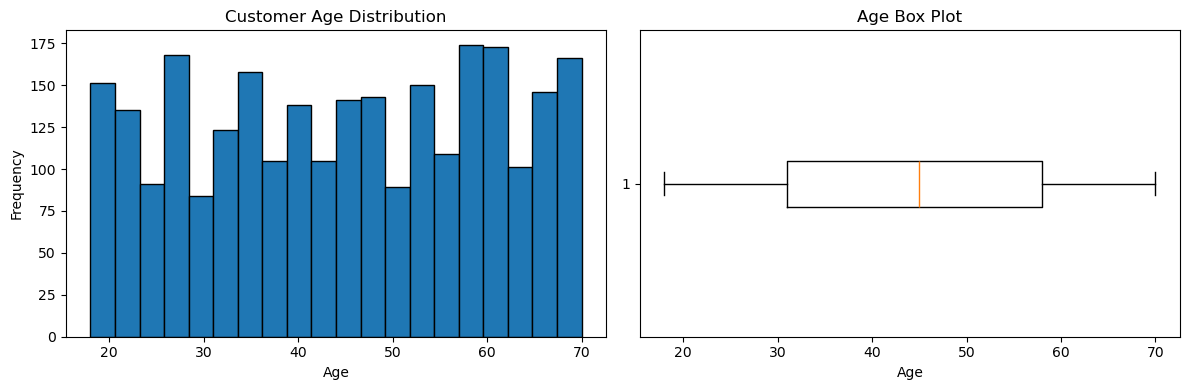

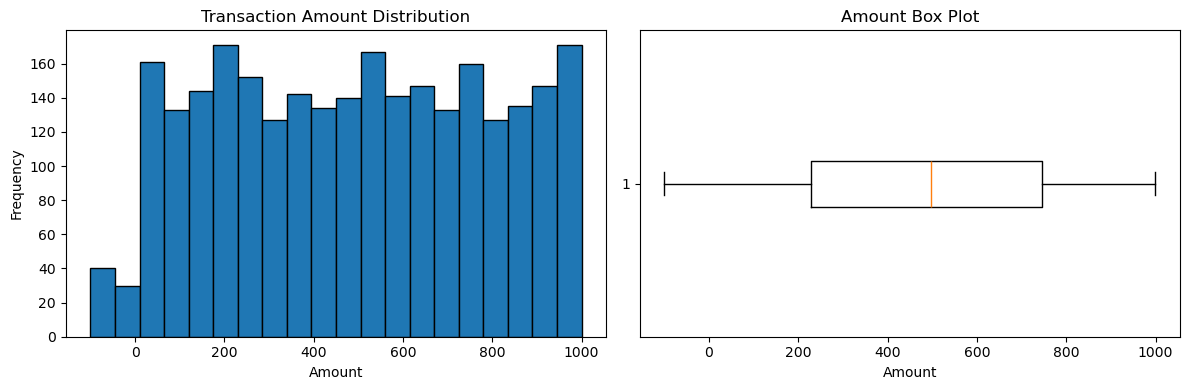

In [14]:

import matplotlib.pyplot as plt

numeric_fields = [
    ("demographics", "Age", "Customer Age Distribution"),
    ("transactions", "Amount", "Transaction Amount Distribution")
]

for dataset_name, column, title in numeric_fields:
    values = datasets[dataset_name][column].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(values, bins=20, edgecolor="black")
    axes[0].set_title(title)
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Frequency")

    axes[1].boxplot(values, vert=False)
    axes[1].set_title(f"{column} Box Plot")
    axes[1].set_xlabel(column)

    plt.tight_layout()
    plt.show()


In [15]:

categorical_columns = {
    "demographics": ["Gender", "Location", "IncomeLevel"],
    "transactions": ["ProductCategory", "PaymentMethod"],
    "social_media": ["Platform", "InteractionType", "Sentiment"]
}

for name, columns in categorical_columns.items():
    df = datasets[name]

    print(f"\n{'=' * 60}")
    print(name.upper())

    for column in columns:
        print(f"\n{column} — counts:")
        print(df[column].value_counts(dropna=False).head(15))

        print(f"\n{column} — percentages:")
        print(
            (df[column].value_counts(normalize=True, dropna=False) * 100)
            .round(2)
            .head(15)
        )



DEMOGRAPHICS

Gender — counts:
Gender
Female    1523
Male      1489
Name: count, dtype: int64

Gender — percentages:
Gender
Female    50.56
Male      49.44
Name: proportion, dtype: float64

Location — counts:
Location
Port Michael         5
New Michael          4
Michaelville         4
Michaelton           4
Port Eric            4
West David           4
West Michael         4
West Robert          4
North Jennifer       4
North Christopher    3
Port Adam            3
Brownbury            3
Kimberlyview         3
Josephburgh          3
East Pamela          3
Name: count, dtype: int64

Location — percentages:
Location
Port Michael         0.17
New Michael          0.13
Michaelville         0.13
Michaelton           0.13
Port Eric            0.13
West David           0.13
West Michael         0.13
West Robert          0.13
North Jennifer       0.13
North Christopher    0.10
Port Adam            0.10
Brownbury            0.10
Kimberlyview         0.10
Josephburgh          0.10
East Pamela 

In [16]:

# 1. Average age by income level
demo = datasets["demographics"]

print("AVERAGE AGE BY INCOME LEVEL")
print(
    demo.groupby("IncomeLevel", dropna=False)["Age"]
    .agg(["count", "mean", "median"])
    .round(2)
)

# 2. Transaction amount by product category
transactions = datasets["transactions"]

print("\nTRANSACTION AMOUNT BY PRODUCT CATEGORY")
print(
    transactions.groupby("ProductCategory", dropna=False)["Amount"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

# 3. Transaction amount by payment method
print("\nTRANSACTION AMOUNT BY PAYMENT METHOD")
print(
    transactions.groupby("PaymentMethod", dropna=False)["Amount"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

# 4. Sentiment distribution by platform
social = datasets["social_media"]

print("\nSENTIMENT BY PLATFORM — COUNTS")
print(
    pd.crosstab(
        social["Platform"],
        social["Sentiment"],
        dropna=False
    )
)

print("\nSENTIMENT BY PLATFORM — ROW PERCENTAGES")
print(
    (
        pd.crosstab(
            social["Platform"],
            social["Sentiment"],
            normalize="index"
        ) * 100
    ).round(1)
)


AVERAGE AGE BY INCOME LEVEL
             count   mean  median
IncomeLevel                      
High           825  45.07    46.0
Low            816  44.22    45.0
Medium         770  45.02    45.0
NaN            239  43.42    43.0

TRANSACTION AMOUNT BY PRODUCT CATEGORY
                 count    mean  median     std
ProductCategory                               
Automotive         489  493.94  508.37  295.12
Clothing           510  492.40  498.28  304.68
Electronics        503  485.76  504.42  288.78
Health & Beauty    467  471.06  462.14  310.34
Home & Garden      479  512.11  515.86  300.19
NaN                254  476.86  461.43  293.69

TRANSACTION AMOUNT BY PAYMENT METHOD
               count    mean  median     std
PaymentMethod                               
Bank Transfer    666  473.93  467.86  305.26
Credit Card      676  499.49  514.88  294.81
Debit Card       686  492.27  492.06  301.49
PayPal           674  493.21  508.07  295.38

SENTIMENT BY PLATFORM — COUNTS
Sentiment  N